# COMP8410 A1 - Week 6: Wan2.2 TI2V-5B vs HunyuanVideo 1.5 (image to video) - Colab
**Run the numbered cells in order. Every code cell starts with `# [n.n]` saying what it does and where to run it.**
**Budget: this pair has ~15 units. Phase 1 on a T4 (about 0.2 units), phase 2 on the A100 (about 1 hour).**

| Section | What | Runtime |
|---|---|---|
| 1 | Setup: Drive, repo | any, fresh runtime (1.2 after a kernel restart) |
| 2 | Install + import check + tests + input photos | **T4 first**, repeat on the A100 (about 5 min, no compiling) |
| 3 | Weights (A100 only: 10 GB Wan + Hunyuan on first load) | A100 |
| 4 | Smoke: 1 item per model, then the BUDGET GATE | A100 |
| 5 | Full run (6 items, seed 0), scoring | A100 (scoring can run on the T4) |
| 6 | Report, cost log, disconnect | end |

Before saving: tick *Omit code cell output when saving*. If a cell fails, STOP and read it; do not use Run all. **Disconnect the runtime when finished (6.3).**

## 1. Setup

In [1]:
# [1.1] SETUP, fresh runtime only: mount Drive, clone the repo, link results/ and outputs/ to Drive
%cd /content
import os
os.environ['HF_HOME'] = '/content/hf'
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
from google.colab import drive # type: ignore
drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/comp8410_a1'
for d in ['results', 'outputs', 'logs', 'w6_data']:
    os.makedirs(f'{BASE}/{d}', exist_ok=True)
!rm -rf /content/a1 && git clone https://github.com/yash1998-MQ-AI/COMP8410-A1-48576158.git /content/a1
%cd "/content/a1/48576158 Evaluation"
!rm -rf results outputs && ln -s {BASE}/results results && ln -s {BASE}/outputs outputs
!nvidia-smi --query-gpu=name,memory.total --format=csv

Mounted at /content/drive
Cloning into '/content/a1'...
remote: Enumerating objects: 417, done.
remote: Counting objects: 100% (417/417), done.
remote: Compressing objects: 100% (262/262), done.
remote: Total 417 (delta 165), reused 390 (delta 138), pack-reused 0 (from 0)
Receiving objects: 100% (417/417), 16.58 MiB | 39.87 MiB/s, done.
Resolving deltas: 100% (165/165), done.
/content/a1/48576158 Evaluation
name, memory.total [MiB]
NVIDIA A100-SXM4-40GB, 40960 MiB


In [11]:
# [1.2] RESTORE after a kernel crash or restart (use INSTEAD of 1.1; the VM files are untouched, only Python variables are lost)
import os
os.environ['HF_HOME'] = '/content/hf'
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
BASE = '/content/drive/MyDrive/comp8410_a1'
%cd "/content/a1/48576158 Evaluation"
from google.colab import drive
drive.mount('/content/drive')
!git -C /content/a1 pull -q

/content/a1/48576158 Evaluation
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Install, import check, tests, inputs (run on the T4 first; repeat on the A100)

In [2]:
# [2.1] INSTALL: clone Wan2.2, install requirements without the torch/numpy/transformers pins, diffusers from source, then an import loop that fixes missing modules
%cd "/content/a1/48576158 Evaluation"
!python pairs/w6_video_generation/install_w6.py 2>&1 | tee {BASE}/logs/w6_install.log | tail -25

/content/a1/48576158 Evaluation
+ git clone --depth 1 https://github.com/Wan-Video/Wan2.2.git /content/Wan2.2
Cloning into '/content/Wan2.2'...
+ git -C /content/Wan2.2 rev-parse HEAD > /content/wan_commit.txt
dropping: ['torch>=2.4.0', 'torchvision>=0.19.0', 'opencv-python>=4.9.0.80', 'transformers>=4.49.0,<=4.51.3', 'tokenizers>=0.20.3', 'dashscope', 'flash_attn', 'numpy>=1.23.5,<2']
+ pip -q install -r /content/w6_req.txt
+ pip -q install git+https://github.com/huggingface/diffusers imageio imageio-ffmpeg opencv-python-headless scikit-image tabulate accelerate sentencepiece protobuf
ils import save_video; from diffusers import HunyuanVideo15ImageToVideoPipeline; from diffusers.utils import export_to_video; print('IMPORTS OK torch', torch.__version__, 'diffusers', diffusers.__version__, 'transformers', transformers.__version__)
                                                                                              ^^^^^^^^^^
  File "/content/Wan2.2/wan/__init__.py", line 4, in 

In [5]:
# [2.2] CPU TESTS for the W6 scorer + save the pinned environment to Drive (evidence)
%cd "/content/a1/48576158 Evaluation"
!python -m pytest -q tests/test_w6.py
!pip freeze > {BASE}/results/w6_ENV.txt
!cp /content/wan_commit.txt {BASE}/results/w6_commit_wan.txt

/content/a1/48576158 Evaluation
..........                                                               [100%]
10 passed in 1.07s


/content/a1/48576158 Evaluation
main_bed_wide: /content/drive/MyDrive/comp8410_a1/w2_listing/main_bed_wide.jpg -> (1280, 720)
main_balcony_view: /content/drive/MyDrive/comp8410_a1/w2_listing/main_balcony_view.jpg -> (1280, 720)
kitchen_b: /content/drive/MyDrive/comp8410_a1/w2_listing/kitchen_b.jpg -> (1280, 720)
bedroom_door: /content/drive/MyDrive/comp8410_a1/w2_listing/bedroom_door.jpg -> (1280, 720)
main_mirror_robe: /content/drive/MyDrive/comp8410_a1/w2_listing/main_mirror_robe.jpg -> (1280, 720)
main_fan_blind: /content/drive/MyDrive/comp8410_a1/w2_listing/main_fan_blind.jpg -> (1280, 720)
6 inputs ready in /content/w6_work/inputs


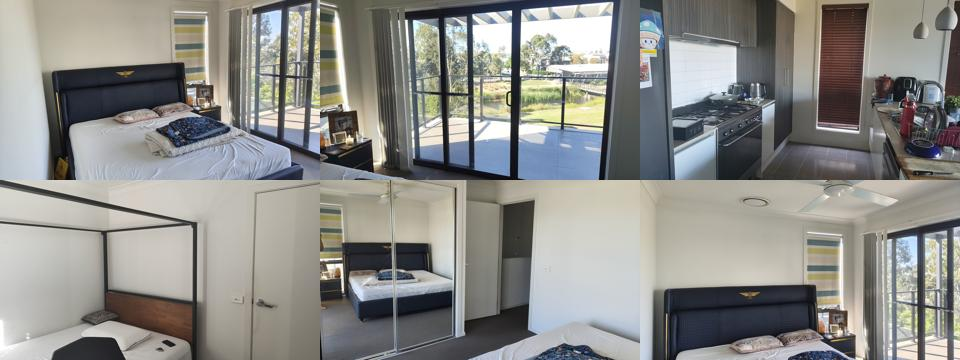

In [3]:
# [2.3] INPUT PHOTOS: find the six listing photos on Drive (W2 copies), crop to 16:9, show the sheet. Same PNGs go to both models.
%cd "/content/a1/48576158 Evaluation"
!python pairs/w6_video_generation/prepare_inputs.py --src {BASE} --out /content/w6_work/inputs
from PIL import Image
display(Image.open('/content/w6_work/inputs/inputs_sheet.jpg'))

## 3. Weights (A100 session)

In [4]:
# [3.1] DOWNLOAD Wan2.2-TI2V-5B (about 10-20 GB). HunyuanVideo-1.5 weights download automatically at the first load in 4.2 (cached in /content/hf).
%cd "/content/a1/48576158 Evaluation"
!python pairs/w6_video_generation/install_w6.py --weights 2>&1 | tail -5
!du -sh /content/ckpt/Wan2.2-TI2V-5B

/content/a1/48576158 Evaluation
  @amp.autocast(enabled=False)
+ python -c "from huggingface_hub import snapshot_download as s; s('Wan-AI/Wan2.2-TI2V-5B', local_dir='/content/ckpt/Wan2.2-TI2V-5B')"
Fetching 23 files: 100%|██████████| 23/23 [01:32<00:00,  4.02s/it]
INSTALL DONE
32G	/content/ckpt/Wan2.2-TI2V-5B


## 4. Smoke tests and the budget gate

In [12]:
# [4.1] SMOKE WAN: first item, seed 0 (loads the model, one cheap warm-up, one full 73-frame clip). Writes results/w6_smoke.jsonl, not the real file.
%cd "/content/a1/48576158 Evaluation"
!python pairs/w6_video_generation/gen_w6.py wan22 --smoke 2>&1 | tee {BASE}/logs/w6_smoke_wan.log | grep -v Warning | tail -30

/content/a1/48576158 Evaluation
  @amp.autocast(enabled=False)
  @amp.autocast(enabled=False)
  @amp.autocast(enabled=False)
  @amp.autocast(enabled=False)
[wan22] flash-attn not available: using the SDPA fallback attention
Loading checkpoint shards: 100%|██████████| 3/3 [00:00<00:00, 55.80it/s]
There are modules in WanModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
  with amp.autocast(dtype=self.dtype):
[wan22] loaded in 92s on NVIDIA A100-SXM4-40GB
  warnings.warn(
100%|██████████| 2/2 [00:02<00:00,  1.28s/it]
  with amp.autocast(dtype=self.dtype):
[wan22] warm-up 92s (not recorded)
100%|██████████| 50/50 [02:57<00:00,  3.55s/it]
[wan22] main_bed_wide s0: ok {'sample': 276.82393259100013, 'encode': 2.5362163409999994}
[wan22] finished: 1 ok, 0 failed


In [13]:
# [4.2] SMOKE HUNYUAN: same, first item. Downloads the weights on first use.
%cd "/content/a1/48576158 Evaluation"
!python pairs/w6_video_generation/gen_w6.py hunyuanvideo15 --smoke 2>&1 | tee {BASE}/logs/w6_smoke_hunyuan.log | grep -v Warning | tail -30

/content/a1/48576158 Evaluation
Loading pipeline components...:   0%|          | 0/10 [00:00<?, ?it/s]Guiders are currently an experimental feature under active development. The API is subject to breaking changes in future releases.

Loading pipeline components...: 100%|██████████| 10/10 [00:03<00:00,  2.85it/s]
[hunyuanvideo15] loaded in 106s on NVIDIA A100-SXM4-40GB
100%|██████████| 2/2 [00:59<00:00, 29.66s/it]
[hunyuanvideo15] warm-up 125s (not recorded)
100%|██████████| 8/8 [01:21<00:00, 10.19s/it]
[hunyuanvideo15] main_bed_wide s0: ok {'sample': 112.59326440899986, 'encode': 1.9017204709998623}
[hunyuanvideo15] finished: 1 ok, 0 failed


In [14]:
# [4.3] BUDGET GATE: projects units for the full run from the smoke latencies. STOP if the projection is over the pair budget.
import json
UNITS_PER_HR = 11.77      # A100 on the Resources panel: check and edit
PAIR_BUDGET = 15.0        # units for the rest of this pair
rows = [json.loads(l) for l in open('results/w6_smoke.jsonl')]
lat = {r['model']: r['value'] for r in rows if r['metric'] == 'latency_s' and r['item_id'] != 'all'}
load = {r['model']: r['value'] for r in rows if r['metric'] == 'load_time_s'}
n = 6
est_s = sum(load.values()) + n * sum(lat.values())
print('latency per clip (s):', lat, '| load (s):', load)
print(f'projected full run: {est_s/60:.0f} min = {est_s/3600*UNITS_PER_HR:.1f} units (budget {PAIR_BUDGET})')
print('GATE', 'PASSED' if est_s / 3600 * UNITS_PER_HR <= PAIR_BUDGET * 0.7 else 'FAILED: cut the item count or frames before running 5.x')

latency per clip (s): {'wan22': 279.3946116929999, 'hunyuanvideo15': 114.56117152399975} | load (s): {'wan22': 91.76478207899981, 'hunyuanvideo15': 106.28825344300026}
projected full run: 43 min = 8.4 units (budget 15.0)
GATE PASSED


/content/a1/48576158 Evaluation
outputs/w6_smoke/hunyuanvideo15/main_bed_wide_s0.mp4 73 frames 24.0 fps (480, 848, 3)


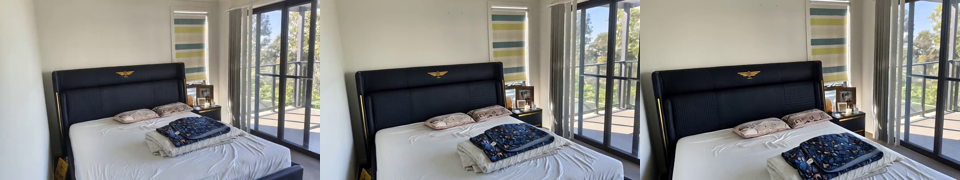

outputs/w6_smoke/wan22/main_bed_wide_s0.mp4 73 frames 24.0 fps (704, 1248, 3)


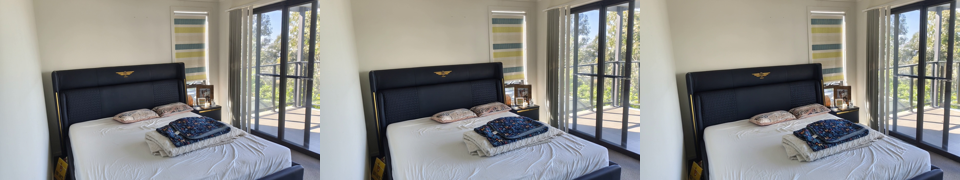

In [15]:
# [4.4] LOOK AT THE SMOKE CLIPS (first frame vs last frame of each)
%cd "/content/a1/48576158 Evaluation"
import glob, numpy as np
from PIL import Image
import sys; sys.path.insert(0, 'pairs/w6_video_generation')
from score_w6 import read_video
for p in sorted(glob.glob('outputs/w6_smoke/*/*.mp4')):
    if '_warmup' in p: continue
    fr, fps = read_video(__import__('pathlib').Path(p))
    print(p, len(fr), 'frames', fps, 'fps', fr[0].shape)
    display(Image.fromarray(np.concatenate([np.asarray(Image.fromarray(fr[i]).resize((320, 180))) for i in (0, len(fr)//2, -1)], axis=1)))

## 5. Full run and scoring (seed 0, 6 items). Resumable: re-running skips finished clips.

In [16]:
# [5.1] FULL RUN: Wan2.2 (all items)
%cd "/content/a1/48576158 Evaluation"
!python pairs/w6_video_generation/gen_w6.py wan22 2>&1 | tee {BASE}/logs/w6_full_wan.log | grep -v Warning | tail -20

/content/a1/48576158 Evaluation
There are modules in WanModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
  with amp.autocast(dtype=self.dtype):
[wan22] loaded in 185s on NVIDIA A100-SXM4-40GB
  warnings.warn(
100%|██████████| 2/2 [00:02<00:00,  1.36s/it]
  with amp.autocast(dtype=self.dtype):
[wan22] warm-up 94s (not recorded)
100%|██████████| 50/50 [02:57<00:00,  3.55s/it]
[wan22] main_bed_wide s0: ok {'sample': 278.69464409600005, 'encode': 2.7743955930000084}
100%|██████████| 50/50 [02:57<00:00,  3.55s/it]
[wan22] main_balcony_view s0: ok {'sample': 278.7858451440002, 'encode': 2.904380057999788}
100%|██████████| 50/50 [02:57<00:00,  3.55s/it]
[wan22] kitchen_b s0: ok {'sample': 277.92289366600016, 'encode': 2.783964359000038}
100%|██████████| 50/50 [02:57<00:00,  3.55s/it]
[wan22] bedroom_door s0: ok {'sample': 275.47571407600026, 'encode': 2.38

In [17]:
# [5.2] FULL RUN: HunyuanVideo 1.5 (all items)
%cd "/content/a1/48576158 Evaluation"
!python pairs/w6_video_generation/gen_w6.py hunyuanvideo15 2>&1 | tee {BASE}/logs/w6_full_hunyuan.log | grep -v Warning | tail -20

/content/a1/48576158 Evaluation
Loading pipeline components...: 100%|██████████| 10/10 [00:03<00:00,  3.17it/s]
[hunyuanvideo15] loaded in 12s on NVIDIA A100-SXM4-40GB
100%|██████████| 2/2 [00:41<00:00, 20.84s/it]
[hunyuanvideo15] warm-up 90s (not recorded)
100%|██████████| 8/8 [01:21<00:00, 10.19s/it]
[hunyuanvideo15] main_bed_wide s0: ok {'sample': 112.61148813900036, 'encode': 1.9434794540002258}
100%|██████████| 8/8 [01:21<00:00, 10.17s/it]
[hunyuanvideo15] main_balcony_view s0: ok {'sample': 111.36494948400014, 'encode': 1.9528988860001846}
100%|██████████| 8/8 [01:21<00:00, 10.13s/it]
[hunyuanvideo15] kitchen_b s0: ok {'sample': 111.05441036899992, 'encode': 1.9144938810004533}
100%|██████████| 8/8 [01:21<00:00, 10.14s/it]
[hunyuanvideo15] bedroom_door s0: ok {'sample': 110.99700274800034, 'encode': 1.8678948859997035}
100%|██████████| 8/8 [01:21<00:00, 10.15s/it]
[hunyuanvideo15] main_mirror_robe s0: ok {'sample': 111.47663429500062, 'encode': 1.9419628669993472}
100%|██████████

In [18]:
# [5.3] SCORE all clips (CPU is fine, GPU faster). Add --rescore to recompute.
%cd "/content/a1/48576158 Evaluation"
!python pairs/w6_video_generation/score_w6.py 2>&1 | tee {BASE}/logs/w6_score.log | grep -v Warning | tail -20

/content/a1/48576158 Evaluation
Loading weights: 100%|██████████| 223/223 [00:00<00:00, 3767.75it/s]
[wan22] main_bed_wide: dino_src 0.979 consec 0.993 motion 0.56
[wan22] main_balcony_view: dino_src 0.974 consec 0.987 motion 1.25
[wan22] kitchen_b: dino_src 0.869 consec 0.965 motion 1.02
[wan22] bedroom_door: dino_src 0.992 consec 0.998 motion 0.19
[wan22] main_mirror_robe: dino_src 0.969 consec 0.989 motion 0.53
[wan22] main_fan_blind: dino_src 0.988 consec 0.996 motion 0.31
[hunyuanvideo15] main_bed_wide: dino_src 0.956 consec 0.988 motion 1.93
[hunyuanvideo15] main_balcony_view: dino_src 0.959 consec 0.984 motion 3.84
[hunyuanvideo15] kitchen_b: dino_src 0.954 consec 0.976 motion 2.23
[hunyuanvideo15] bedroom_door: dino_src 0.940 consec 0.975 motion 2.44
[hunyuanvideo15] main_mirror_robe: dino_src 0.889 consec 0.967 motion 4.64
[hunyuanvideo15] main_fan_blind: dino_src 0.935 consec 0.981 motion 1.02


## 6. Results, cost, shut down

/content/a1/48576158 Evaluation
          metric  n_items  wan22  wan22_lo  wan22_hi  hunyuanvideo15  hunyuanvideo15_lo  hunyuanvideo15_hi  diff_A_minus_B  diff_lo  diff_hi  A_higher  B_higher             verdict
 clip_i_src_mean        6  0.960     0.913     0.987           0.913              0.882              0.940           0.047    0.006    0.092         5         1            A higher
   dino_src_mean        6  0.962     0.924     0.986           0.939              0.917              0.955           0.023   -0.023    0.057         5         1 no clear difference
    dino_src_min        6  0.934     0.868     0.976           0.902              0.867              0.931           0.032   -0.045    0.095         5         1 no clear difference
     dino_consec        6  0.988     0.978     0.995           0.978              0.973              0.984           0.010   -0.000    0.018         5         1 no clear difference
first_frame_ssim        6  0.987     0.984     0.991           

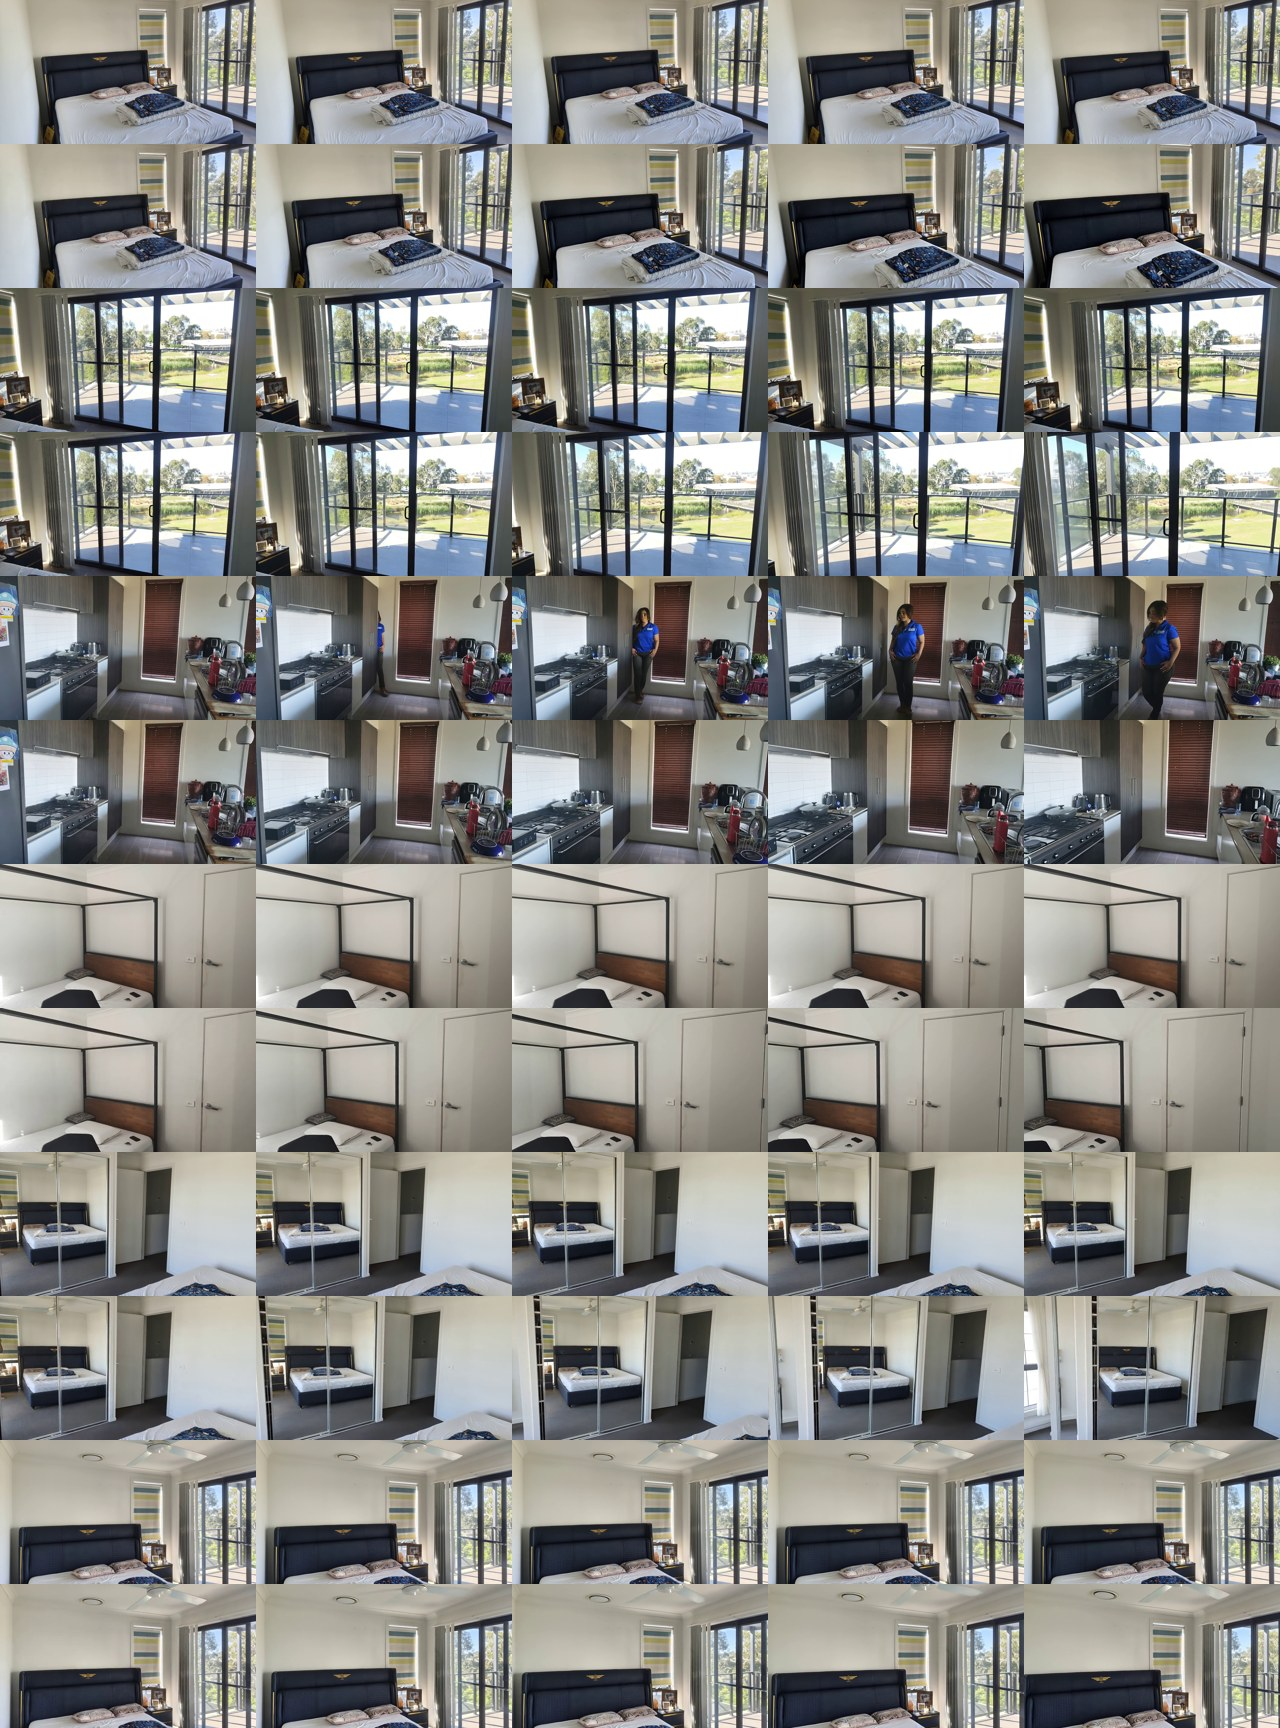

In [19]:
# [6.1] TABLES, CHARTS, FRAME STRIPS; copies report assets to Drive. The strips show the rooms: keep 'Omit code cell output' ticked.
%cd "/content/a1/48576158 Evaluation"
!python pairs/w6_video_generation/report_w6.py --show 2>&1 | tee {BASE}/logs/w6_report.log | grep -v Warning
!mkdir -p {BASE}/report_assets && cp -r report_assets/w6 {BASE}/report_assets/
from PIL import Image
display(Image.open('outputs/w6_figures/w6_strips.jpg'))

In [20]:
# [6.2] COST LOG: fill in HOURS (connected GPU time) and UNITS_PER_HR (Resources panel), run once per session
%cd "/content/a1/48576158 Evaluation"
HOURS = None          # e.g. 1.2
UNITS_PER_HR = None   # e.g. 11.77
if HOURS and UNITS_PER_HR:
    from a1eval import log_cost
    log_cost('cost_log.csv', '2026-11-02', 'Colab Pro', 'A100-40GB', HOURS, UNITS_PER_HR * 0.1513, note='W6 install + generation + scoring')
    !tail -3 cost_log.csv

/content/a1/48576158 Evaluation


In [22]:
# [6.3] FREE THE GPU: set AUTO_DISCONNECT = True once everything is copied to Drive
AUTO_DISCONNECT = True
if AUTO_DISCONNECT:
    from google.colab import runtime
    runtime.unassign()